Incorporate into function to run all with variables: channel list, chromophore, age, location

In [ ]:
%reset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
import skfda
import sys

from matplotlib import cm
from scipy.integrate import simpson
from skfda.preprocessing.dim_reduction import FPCA
from skfda.representation.basis import BSplineBasis

sys.path.append("[insert root path]/fcpt/functions")
import fNIRSData
import funcChangePoint
import auxFuncChPt

import importlib
importlib.reload(fNIRSData)
importlib.reload(funcChangePoint)
importlib.reload(auxFuncChPt)

plt.rcParams["figure.figsize"] = [6.5,6.5]
plt.rcParams["text.usetex"] = True
%matplotlib inline

Nothing done.


Define input file/output filename (if you want to save) and the channels you wish to analyse (i,e. ROI channels)
<br> If adding more channels, the blocks of code which need to be included in a for loop are indicated below in the notebook.

In [ ]:
location = 'GM'
agePoint = 12
numChan = 3 #run on channels =  [3, 4, 8, 9, 12, 18, 19] for all ROI channels
firstTrial = 1
lastTrial = 25
dataFile = '[insert root path]/fcpt/dataRaw/homer2'+str(location)+str(agePoint)+'moDataFrame.pkl'
#outputFilename = '/Users/sambe/Documents/Python_Projects/FDA/data/homer2'+str(location)+str(agePoint)+'moHbOChPtFF.pkl'

In [348]:
firstFunc = firstTrial-1
lastFunc = lastTrial-1
numChrom = 1
firstSamp = -20
lastSamp = 182
gridPoints = np.arange(firstSamp, lastSamp, 1)

In [349]:
columnList = ['Channel',
'Chromophore',
'First Trial',
'Last Trial',
'Change Point',
'Max. T_N',
'p-value']

dfChangePoint = pd.DataFrame(columns = columnList)

If working with multiple channels, group the following 5 blocks of code together and run inside a for loop, i.e.:
<br> for numChan in channels: 

In [350]:
dataMatrix = fNIRSData.groupDataMatrix(dataFile,
                                    numChan,
                                    numChrom,
                                    firstTrial,
                                    lastTrial)

In [351]:
fd = skfda.FDataGrid(
    data_matrix=dataMatrix,
    grid_points=gridPoints,
)

In [352]:
dHat = auxFuncChPt.cumulPercVariance(fd)

In [353]:
chanMat = (auxFuncChPt.findCPtsFPCA(dataMatrix, firstFunc, lastFunc, dHat = dHat)).astype('float32')

chanMat = np.delete(chanMat, (0), axis=0)


In [354]:
for i in range(chanMat.shape[0]):
    dfChangePoint = pd.concat([dfChangePoint, pd.DataFrame.from_records([{
        'Channel':numChan,
        'Chromophore':numChrom,
        'First Trial':(chanMat[i][0]+1),
        'Last Trial': (chanMat[i][1]+1),
        'Change Point': (chanMat[i][2]+1),
        'Max. T_N': (chanMat[i][3]),
        'p-value': (chanMat[i][4])
        }])])

In [355]:
dfChangePoint

,Channel,Chromophore,First Trial,Last Trial,Change Point,Max. T_N,p-value
0,3,1,1.0,25.0,14.0,3.491205,0.00064
0,3,1,1.0,13.0,6.0,2.290766,0.00430
0,3,1,1.0,5.0,3.0,0.938904,0.04989
0,3,1,3.0,5.0,5.0,0.580304,0.06237
0,3,1,6.0,13.0,9.0,1.289202,0.03366
0,3,1,6.0,8.0,7.0,0.215241,0.25637
0,3,1,9.0,13.0,10.0,0.312037,0.37403
0,3,1,14.0,25.0,25.0,0.350494,0.55274


In [356]:
#save the participant's nested dictionary
#with open(outputFilename, 'wb') as f:
#    pickle.dump(dfChangePoint, f)

In [357]:
df = dfChangePoint[dfChangePoint['p-value'] <= 0.05]

In [358]:
dfChan = (df[df['Channel'] == numChan]).sort_values(by=['Change Point'])

changeColumn = (dfChan.get('Change Point').tolist())
changeColumn = [int(x) for x in changeColumn]
changeColumn.append(lastTrial + 1)

In [359]:
iBlock = 0
tempTrial = 1

blockMeans = np.empty([len(changeColumn), (abs(firstSamp)+abs(lastSamp))])
for point in changeColumn:
    firstTrial = tempTrial
    lastTrial = point-1 #-1 because dataMatrix rows go from 0->(numTrials-1)
    blockMatrix = dataMatrix[firstTrial-1:lastTrial-1, ]
    blockMeans[iBlock] = np.mean(blockMatrix, axis = 0)
    tempTrial = point
    iBlock = iBlock + 1

In [360]:
changeColumn.insert(0,1)
volChans = []

volNoHab = simpson(blockMeans[0, 21:], dx = 1) * lastTrial
volHab = 0
for i in range(0, len(changeColumn)-1):
    volTrial = (simpson(blockMeans[i, 21:], dx = 1)) * (changeColumn[i+1] - changeColumn[i])
    volHab = volHab + volTrial

In [361]:
ratioHab = (volHab / volNoHab)
volChans.append(ratioHab)
print(ratioHab)

0.6772606521398176


In [362]:
df

,Channel,Chromophore,First Trial,Last Trial,Change Point,Max. T_N,p-value
0,3,1,1.0,25.0,14.0,3.491205,0.00064
0,3,1,1.0,13.0,6.0,2.290766,0.00430
0,3,1,1.0,5.0,3.0,0.938904,0.04989
0,3,1,6.0,13.0,9.0,1.289202,0.03366


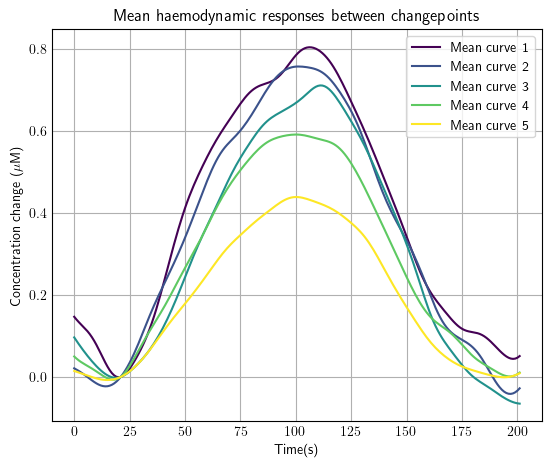

In [396]:
#plotting here works well on 12mo GM channel 3
trialFrame = pd.DataFrame(data=blockMeans*1000000)
trialFrame = trialFrame.T
trialFrame.columns = trialFrame.columns + 1

ax = trialFrame.plot(figsize=[5,4], 
                cmap = cm.viridis,
                xlabel = 'Time(s)', 
                ylabel = 'Concentration change ($\mu$M)',
                title = 'Mean haemodynamic responses between changepoints',
)

curveNames = [f'Mean curve {i}' for i in range(1, np.shape(trialFrame)[1]+1)]

# Adding legend with custom labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, curveNames)

In [1]:
plt.style.use('_mpl-gallery')

# Make data
Y = np.arange(0, dataMatrix.shape[0])
X = np.arange(0, dataMatrix.shape[1])

X, Y = np.meshgrid(X, Y)

fig = plt.figure(figsize=[8,7]) # !! Change figure size here!! 
ax = fig.add_subplot( projection="3d")
ax.set_zlabel('Concentration change ($\mu$M)') #can't set z label using plt
ax.set_box_aspect(aspect=None, zoom=0.95) #so z label can be seen

#using blues:
#ax.plot_surface(Y, X, dataMatrix, cmap=cm.Blues, lw=0.5, rstride=1, cstride=1)

#colourblind friendly:
ax.plot_surface(Y, X, dataMatrix, cmap = cm.viridis, lw=0.5, rstride=1, cstride=1)
ax.set_box_aspect((1.5, 1, 0.6))

plt.title('Mean haemodynamic responses in channel '+str(numChan)+' across all '+str(agePoint)+'mo participants')
plt.xlabel('Trial') 
plt.ylabel('Time (ds)')

plt.show()

NameError: name 'plt' is not defined

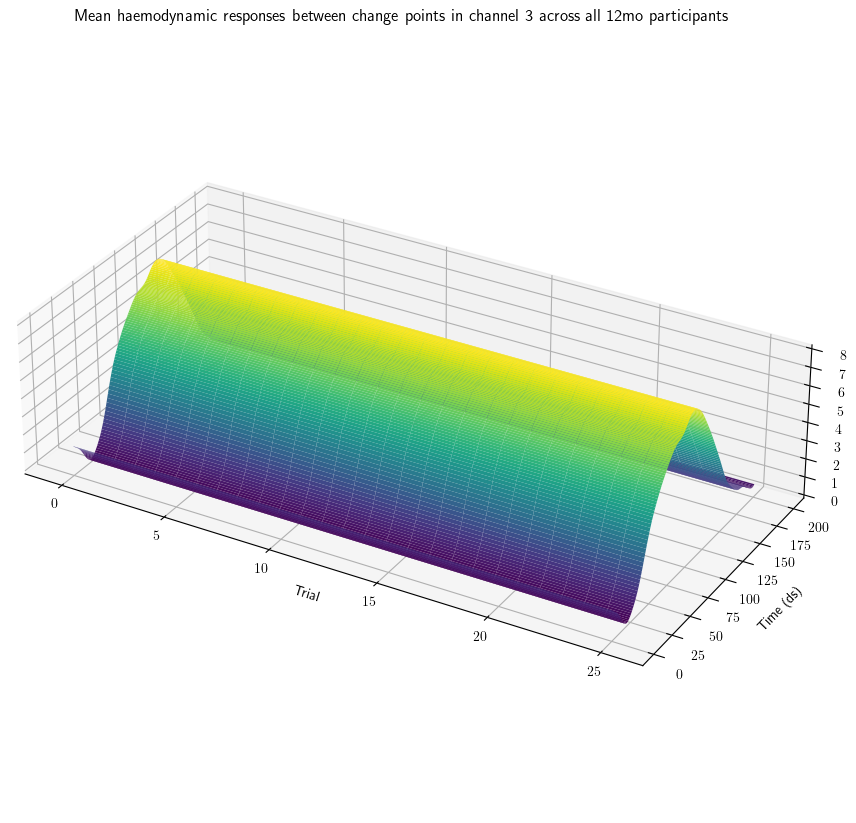

In [382]:
blockSurfGrid = np.empty([dataMatrix.shape[0]*1000, dataMatrix.shape[1]])
for i in range(0, dataMatrix.shape[0]*1000):
    posTemp = ([j for j in range(1) if changeColumn[j] <= (i/1000)+1])
    blockSurfGrid[i] = blockMeans[max(posTemp)]
    
plt.style.use('_mpl-gallery')

# Make data
Y = np.arange(0, dataMatrix.shape[0], 0.001)
X = np.arange(0, dataMatrix.shape[1])

X, Y = np.meshgrid(X, Y)

fig = plt.figure(figsize=[8,8]) # !! Change figure size here!! 
ax = fig.add_subplot( projection="3d")
ax.grid(b = True, which = 'major')
ax.set_zlabel('Concentration change ($\mu$M)') #can't set z label using plt
ax.set_box_aspect(aspect=None, zoom=0.95) #so z label can be seen

#using blues:
#ax.plot_surface(Y, X, dataMatrix, cmap=cm.Blues, lw=0.5, rstride=1, cstride=1)

#colourblind friendly:
ax.plot_surface(Y, X, blockSurfGrid, cmap=cm.viridis, lw=0.5, rstride=1000, cstride=1)


plt.grid(visible = True, which = 'major')
plt.title('Mean haemodynamic responses between change points in channel '+str(numChan)+' across all '+str(agePoint)+'mo participants')
plt.xlabel('Trial') 
plt.ylabel('Time (ds)')

plt.show()

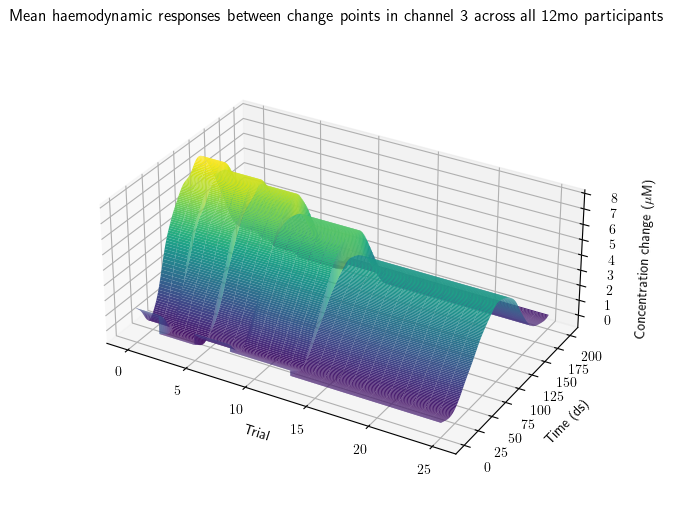

In [404]:
blockSurfGrid = np.empty([dataMatrix.shape[0]*1000, dataMatrix.shape[1]])
for i in range(0, dataMatrix.shape[0]*1000):
    posTemp = ([j for j in range(len(changeColumn)) if changeColumn[j] <= (i/1000)+1])
    blockSurfGrid[i] = blockMeans[max(posTemp)]
    
plt.style.use('_mpl-gallery')

# Make data
Y = np.arange(0, dataMatrix.shape[0], 0.001)
X = np.arange(0, dataMatrix.shape[1])

X, Y = np.meshgrid(X, Y)

fig = plt.figure(figsize=[5,5]) # !! Change figure size here!! 
ax = fig.add_subplot( projection="3d")
ax.grid(b = True, which = 'major')
ax.set_zlabel('Concentration change ($\mu$M)') #can't set z label using plt
ax.set_box_aspect(aspect=None, zoom=0.95) #so z label can be seen

#using blues:
#ax.plot_surface(Y, X, dataMatrix, cmap=cm.Blues, lw=0.5, rstride=1, cstride=1)

#colourblind friendly:
ax.plot_surface(Y, X, blockSurfGrid, cmap=cm.viridis, lw=0.5, rstride=1000, cstride=1)
ax.set_box_aspect((1.5, 1, 0.6))

plt.grid(visible = True, which = 'major')
plt.title('Mean haemodynamic responses between change points in channel '+str(numChan)+' across all '+str(agePoint)+'mo participants')
plt.xlabel('Trial') 
plt.ylabel('Time (ds)')

plt.show()

Use group derived change points to find volumetric data for each individual participant:

In [368]:
with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)

partIDs = dfFull.ID.unique()
partIDs = np.sort(partIDs)
numParts = partIDs.size #number of participants
numSamps = abs(firstSamp)+abs(lastSamp) #number of sampled values/size of trial block

chanData = np.empty([numParts, lastTrial, numSamps]) #initialise
iPart = 0 #initialise
nanParts = []

for iPart in range(numParts-1,0,-1):
    dfPart = dfFull[(dfFull.ID == partIDs[iPart]) & (dfFull.Chrom == numChrom) & (dfFull.Channel == numChan)]
    for iTrial in range(lastTrial):
        trialData = dfPart[dfPart.Trial == iTrial+1]['Time series']
        trialData = trialData.to_numpy() #allows insertion into matrix
        if np.mean(trialData[0]) < -99: #check for user-inserted values detailing various errors (all < -101)
            chanData[iPart, iTrial, :] = np.nan
        else:
            chanData[iPart, iTrial, :] = trialData[0]
    iPart+=1

In [369]:
#create DF for data
#calculate mean curves between GROUP DERIVED change points
#calculate hab. volume
#calculate non-hab volume
#calculate ratio and store



Find individual change points (will utilise fewer participants here as needs all trials for fPCA -> participants with rejected trials will be deleted)

In [370]:
with open(dataFile, 'rb') as f:
        dfFull = pickle.load(f)

partIDs = dfFull.ID.unique()
partIDs = np.sort(partIDs)
numParts = partIDs.size #number of participants
numSamps = abs(firstSamp)+abs(lastSamp) #number of sampled values/size of trial block

chanData = np.empty([numParts, lastTrial, numSamps]) #initialise
iPart = 0 #initialise
nanParts = 0

for iPart in range(numParts-1,0,-1):
    dfPart = dfFull[(dfFull.ID == partIDs[iPart]) & (dfFull.Chrom == numChrom) & (dfFull.Channel == numChan)]
    for iTrial in range(lastTrial):
        trialData = dfPart[dfPart.Trial == iTrial+1]['Time series']
        trialData = trialData.to_numpy() #allows insertion into matrix
        if np.mean(trialData[0]) < -99: #check for user-inserted values detailing various errors (all < -101)
            chanData = chanData = np.delete(chanData, iPart, axis = 0) #remove participants with incomplete data as can't perform fPCA on these
            nanParts+=1
            break
        else:
            chanData[iPart, iTrial, :] = trialData[0]
    iPart+=1

In [371]:
fd = skfda.FDataGrid(
    data_matrix=chanData[0,:,:],
    grid_points=gridPoints,
)
dHat = auxFuncChPt.cumulPercVariance(fd)

/Users/sambe/.pyenv/versions/3.9.16/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:545: RuntimeWarning: divide by zero encountered in divide
  explained_variance_ratio_ = explained_variance_ / total_var
/Users/sambe/.pyenv/versions/3.9.16/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:545: RuntimeWarning: invalid value encountered in divide
  explained_variance_ratio_ = explained_variance_ / total_var


In [372]:
#look at indivFPCAChangePoint for foundations of code